# Training Engineering and Model Assessment

**Task:** predict earthquake magnitude from single-station PNSN waveforms, and assess how training strategy (splitting, cross-validation, bootstrapping, bagging) changes what we can honestly claim about the model.

**Protocol used in this notebook**

| Stage | Data | Used for |
| :--- | :--- | :--- |
| Development (train + validation) | first 85% of events in time | every modelling decision: CV-scheme comparison, hyperparameter search, learning curves, bootstrapping, bagging, subset analysis |
| Validation | 5 contiguous time blocks of the development events (blocked, event-grouped CV); block 5 doubles as the fixed validation block for per-round curves | model selection |
| Test | last 15% of events in time | touched **once**, in Section 9, after the final model is frozen |

Every number reported below is computed on held-out data (out-of-fold validation predictions or the test set). Training-set scores appear only as labelled reference lines in the learning-curve figures.

**Note on inputs.** `AutoML_Hyperparameter_Tuning.ipynb` used the first 300 samples of each trace. The traces are 150 s long (15,001 samples) and the P arrival is never earlier than sample 5,006, so that window is pre-event noise and carries no magnitude information. Here the features are computed from windows anchored on the P and S picks.

In [1]:
import os, time, warnings
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import loguniform, randint

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (BaggingRegressor, HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import (GroupKFold, KFold, RandomizedSearchCV,
                                     cross_val_predict)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=ConvergenceWarning)
os.environ["PYTHONWARNINGS"] = "ignore:Stochastic Optimizer"   # same filter inside joblib worker processes

SEED = 42
N_JOBS = 6          # physical cores; more workers used too much memory
FS = 100            # sampling rate (Hz)

# Plot style: fixed colour per entity, recessive grid and axes
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "magenta": "#e87ba4", "violet": "#6250d6", "muted": "#898781", "ink": "#0b0b0b"}
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.markersize": 6,
})

def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))

def metrics(y, p):
    # Held-out error metrics. Bias = mean(prediction - truth).
    return {"RMSE": rmse(y, p), "MAE": float(mean_absolute_error(y, p)),
            "R2": float(r2_score(y, p)), "Bias": float(np.mean(np.asarray(p) - np.asarray(y)))}

## 1. Data and features

Each sample is one station recording of one event. The target is the catalog magnitude (`preferred_source_magnitude`).

Features use only what a station operator has at prediction time: the vertical-component waveform (the only channel present on all recordings; 65% of traces are single-component `EH`), the P and S picks, and the channel type. No event location, depth, station identity or coordinates are used, so the model cannot memorise events or stations by ID.

| Group | Features | Why |
| :--- | :--- | :--- |
| Amplitude | log10 peak and RMS in the P window, S window and whole signal; pre-P noise RMS; SNR | magnitude scales with log amplitude |
| Duration | log10 coda duration (time until the 2 s moving RMS returns to 2x / 4x noise) | 99% of labels are duration magnitudes (`md`) |
| Spectrum | log10 mean power in six octave bands (0.5–32 Hz), spectral centroid | corner frequency moves with magnitude |
| Distance proxy | S − P time and its log | amplitude decays with distance |
| Instrument | channel type one-hot (`EH`/`BH`/`HH`), clipped-sample fraction | amplitudes are raw counts, gain differs by instrument |

In [2]:
repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
clean_meta_path = os.path.join(repo_root, "data", "clean", "metadata_clean.parquet")
raw_wave_path = os.path.join(repo_root, "data", "raw", "waveforms.hdf5")
feature_cache = os.path.join(repo_root, "data", "ai_ready", "waveform_features.parquet")

meta = pd.read_parquet(clean_meta_path).reset_index(drop=True)
meta["origin_time"] = pd.to_datetime(meta["source_origin_time"])

BANDS = [(0.5, 1), (1, 2), (2, 4), (4, 8), (8, 16), (16, 32)]

def trace_features(x, p, s):
    # Features for one (3, 15001) trace from the vertical channel and the P/S pick samples.
    z_raw = np.asarray(x[2], dtype=np.float64)
    n = z_raw.size
    noise_sl = slice(max(0, p - 3000), p - 100)           # 29 s of pre-P noise
    z = z_raw - z_raw[noise_sl].mean()
    eps = 1e-3
    noise_rms = z[noise_sl].std() + eps
    p_end = max(min(s, p + 500), p + 50)
    p_win, s_win, sig = z[p:p_end], z[s:min(s + 1000, n)], z[p:min(p + 6000, n)]
    f = {"log_noise_rms": np.log10(noise_rms),
         "log_p_peak": np.log10(np.abs(p_win).max() + eps),
         "log_p_rms": np.log10(p_win.std() + eps),
         "log_s_peak": np.log10(np.abs(s_win).max() + eps),
         "log_s_rms": np.log10(s_win.std() + eps),
         "log_peak": np.log10(np.abs(sig).max() + eps)}
    f["log_snr"] = f["log_peak"] - f["log_noise_rms"]
    # Coda duration from the 2 s moving-RMS envelope
    w = 200
    c = np.concatenate([[0.0], np.cumsum(z[p:] ** 2)])
    env = np.sqrt((c[w:] - c[:-w]) / w)
    i_pk = int(env.argmax())
    for k in (2, 4):
        below = np.nonzero(env[i_pk:] < k * noise_rms)[0]
        dur = (i_pk + below[0]) if below.size else env.size
        f[f"log_coda_dur_{k}x"] = np.log10((dur + 1) / FS)
    f["coda_censored"] = float(below.size == 0)           # coda still above 4x noise at trace end
    # Spectrum of the first 30 s after P
    seg = z[p:min(p + 3000, n)]
    spec = np.abs(np.fft.rfft(seg * np.hanning(seg.size))) ** 2
    fr = np.fft.rfftfreq(seg.size, 1 / FS)
    for lo, hi in BANDS:
        f[f"log_pow_{lo}_{hi}Hz"] = np.log10(spec[(fr >= lo) & (fr < hi)].mean() + eps)
    m = (fr >= 0.5) & (fr < 40)
    f["spec_centroid_hz"] = float((fr[m] * spec[m]).sum() / (spec[m].sum() + eps))
    a = np.abs(z_raw[p:min(p + 6000, n)] - np.median(z_raw))
    f["clip_frac"] = float((a >= 0.98 * a.max()).mean()) if a.max() > 0 else 0.0
    f["sp_time_s"] = (s - p) / FS
    f["log_sp_time"] = np.log10((s - p) / FS)
    return f

if os.path.exists(feature_cache):
    feats = pd.read_parquet(feature_cache)
    assert (feats.pop("trace_name").to_numpy() == meta["trace_name"].to_numpy()).all()
    print("Loaded cached features:", feature_cache)
else:
    start = time.time()
    rows = {}
    with h5py.File(raw_wave_path, "r") as hf:
        grp = hf["data"]
        for i in meta.sort_values(["bucket", "tindex"]).index:      # sequential disk reads
            r = meta.loc[i]
            rows[i] = trace_features(grp[f"bucket{r.bucket}"][r.tindex],
                                     int(r.trace_P_arrival_sample), int(r.trace_S_arrival_sample))
    feats = pd.DataFrame.from_dict(rows, orient="index").loc[meta.index]
    feats.assign(trace_name=meta["trace_name"]).to_parquet(feature_cache, index=False)
    print(f"Extracted features in {time.time() - start:.0f} s -> {feature_cache}")

for ch in ["EH", "BH", "HH"]:
    feats[f"chan_{ch}"] = (meta["station_channel_code"] == ch).astype(float)

FEATURES = list(feats.columns)
assert np.isfinite(feats.to_numpy()).all()
print("Recordings:", len(meta), "| features:", len(FEATURES))

Loaded cached features: /home/nharr/MLGEO_AU26_seismology/data/ai_ready/waveform_features.parquet
Recordings: 18640 | features: 23


## 2. Correlation structure of the data

The splitting scheme has to follow how the samples depend on each other, so that is measured first.

In [3]:
y_all = meta["preferred_source_magnitude"].to_numpy()
per_event = meta.groupby("event_id").size()
per_station = meta.groupby("station_code").size()

print(f"Events: {len(per_event)}   recordings per event: mean {per_event.mean():.2f}, max {per_event.max()}")
print(f"Recordings that share their event with another recording: {(meta['event_id'].map(per_event) > 1).mean():.1%}")
print(f"Distinct magnitudes within one event (max over events): {meta.groupby('event_id')['preferred_source_magnitude'].nunique().max()}")
print(f"Stations: {len(per_station)}   top 10 stations hold {per_station.nlargest(10).sum() / len(meta):.1%} of recordings")

# Share of variance explained by group membership (between-group / total)
def group_variance_share(values, groups):
    v = pd.Series(np.asarray(values, dtype=float))
    g = pd.Series(np.asarray(groups))
    return float(((v.groupby(g).transform("mean") - v.mean()) ** 2).mean() / v.var(ddof=0))

struct = pd.DataFrame({
    col: {"by event": group_variance_share(vals, meta["event_id"]),
          "by station": group_variance_share(vals, meta["station_code"])}
    for col, vals in [("magnitude (target)", y_all), ("log_peak", feats["log_peak"]),
                      ("log_coda_dur_2x", feats["log_coda_dur_2x"]), ("log_noise_rms", feats["log_noise_rms"])]
}).T
print("\nShare of variance explained by group membership:")
print(struct.round(2).to_string())

# Temporal dependence: autocorrelation of event magnitude in origin-time order
ev = meta.groupby("event_id").agg(t=("origin_time", "first"), mag=("preferred_source_magnitude", "first")).sort_values("t")
m = ev["mag"].to_numpy() - ev["mag"].mean()
print("\nAutocorrelation of event magnitude at lag k (events in time order):")
print("  ".join(f"k={k}: {np.corrcoef(m[:-k], m[k:])[0, 1]:+.2f}" for k in (1, 2, 5, 20, 100)))

Events: 8055   recordings per event: mean 2.31, max 17
Recordings that share their event with another recording: 82.4%
Distinct magnitudes within one event (max over events): 1
Stations: 281   top 10 stations hold 31.0% of recordings

Share of variance explained by group membership:
                    by event  by station
magnitude (target)      1.00        0.21
log_peak                0.63        0.27
log_coda_dur_2x         0.57        0.13
log_noise_rms           0.52        0.69

Autocorrelation of event magnitude at lag k (events in time order):
k=1: +0.14  k=2: +0.13  k=5: +0.12  k=20: +0.10  k=100: +0.05


**Reading.** Three dependence structures matter:

1. **Event groups (the strongest).** The label is a property of the event, so all recordings of an event carry the *same* target. A row-wise random split puts sibling recordings on both sides and lets a flexible model match them.
2. **Station groups.** Noise level and raw-count amplitude are largely station properties (instrument gain, site), so recordings at one station are not independent either.
3. **Time.** Events arrive in swarms and aftershock sequences, and network instrumentation changes between 2002 and 2008; successive events are correlated.

**Choice: event-grouped, time-blocked splits.** Events are sorted by origin time and cut into contiguous blocks. No event is ever split (handles 1), and train/validation periods do not interleave (handles 3). Station dependence (2) is handled as a generality test (leave-stations-out) in Section 8 rather than in the main split, because a new event at a known station is the expected use case. `TimeSeriesSplit` (forward chaining) is also run as a check in Section 8; it is not the primary scheme because the features contain no lagged values and it would discard the early blocks as validation data.

The repository's existing `partitions.parquet` (station holdout) is not used as the test set: 1,230 events have recordings in both its train and test partitions, so the same label sits on both sides.

## 3. Train / validation / test split

        split  recordings  events       from         to  broadband (BH/HH) share  mean magnitude
  dev block 1        3158    1370 2002-01-01 2003-01-17                     0.15            1.25
  dev block 2        3240    1369 2003-01-18 2004-03-31                     0.24            1.28
  dev block 3        2728    1370 2004-03-31 2005-04-10                     0.25            1.37
  dev block 4        3095    1369 2005-04-11 2006-08-13                     0.29            1.23
  dev block 5        3011    1369 2006-08-13 2007-05-08                     0.43            1.50
TEST (locked)        3408    1208 2007-05-09 2008-12-05                     0.49             NaN

(The test set's target statistics are deliberately not computed here.)


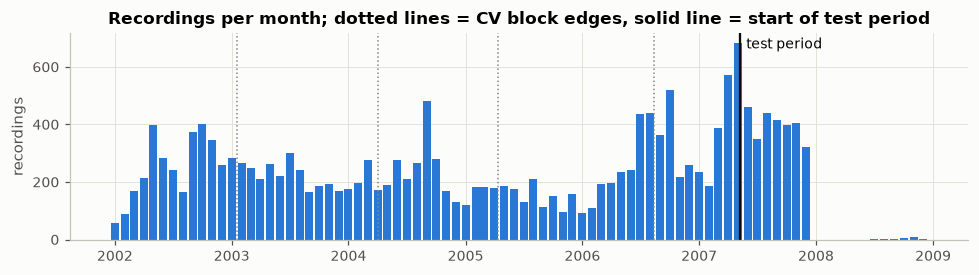

In [4]:
TEST_FRACTION = 0.15
N_BLOCKS = 5

event_time = meta.groupby("event_id")["origin_time"].first().sort_values()
n_test_events = int(round(TEST_FRACTION * len(event_time)))
dev_events, test_events = event_time.index[:-n_test_events], event_time.index[-n_test_events:]

is_test = meta["event_id"].isin(test_events).to_numpy()
TEST_ROWS = np.where(is_test)[0]          # not indexed again until Section 9
TEST_USED = False

# Development data: everything below this line (until Section 9) only sees these arrays
dev = meta.loc[~is_test].reset_index(drop=True)
X_dev = feats.loc[~is_test].to_numpy()
y_dev = dev["preferred_source_magnitude"].to_numpy()
ev_dev = dev["event_id"].to_numpy()

# Blocked, event-grouped CV: contiguous time blocks of development events
event_block = pd.Series(np.arange(len(dev_events)) * N_BLOCKS // len(dev_events), index=dev_events)
block = dev["event_id"].map(event_block).to_numpy()
blocked_cv = [(np.where(block != k)[0], np.where(block == k)[0]) for k in range(N_BLOCKS)]

# Fixed split for per-round curves: train on blocks 1-4, validate on block 5 (latest dev period)
fit_idx, val_idx = np.where(block < N_BLOCKS - 1)[0], np.where(block == N_BLOCKS - 1)[0]

assert set(dev["event_id"]).isdisjoint(set(meta.loc[is_test, "event_id"]))
for tr, va in blocked_cv:
    assert set(ev_dev[tr]).isdisjoint(set(ev_dev[va]))
assert dev["origin_time"].max() < meta.loc[is_test, "origin_time"].min()

summary = pd.DataFrame(
    [{"split": f"dev block {k + 1}", "recordings": int((block == k).sum()),
      "events": int((event_block == k).sum()),
      "from": dev.loc[block == k, "origin_time"].min().date(), "to": dev.loc[block == k, "origin_time"].max().date(),
      "broadband (BH/HH) share": (dev.loc[block == k, "station_channel_code"] != "EH").mean(),
      "mean magnitude": y_dev[block == k].mean()} for k in range(N_BLOCKS)]
    + [{"split": "TEST (locked)", "recordings": int(is_test.sum()), "events": n_test_events,
        "from": meta.loc[is_test, "origin_time"].min().date(), "to": meta.loc[is_test, "origin_time"].max().date(),
        "broadband (BH/HH) share": (meta.loc[is_test, "station_channel_code"] != "EH").mean(), "mean magnitude": np.nan}])
print(summary.round(2).to_string(index=False))
print("\n(The test set's target statistics are deliberately not computed here.)")

fig, ax = plt.subplots(figsize=(9, 2.6))
month = meta["origin_time"].dt.tz_localize(None).dt.to_period("M").dt.to_timestamp()
counts = month.value_counts().sort_index()
ax.bar(counts.index, counts.values, width=25, color=C["blue"])
edges = [dev.loc[block == k, "origin_time"].min() for k in range(1, N_BLOCKS)]
for e in edges:
    ax.axvline(e.tz_localize(None), color=C["muted"], lw=1, ls=":")
t0 = meta.loc[is_test, "origin_time"].min().tz_localize(None)
ax.axvline(t0, color=C["ink"], lw=1.5)
ax.annotate("test period", (t0, ax.get_ylim()[1]), xytext=(4, -10), textcoords="offset points", fontsize=9)
ax.set_title("Recordings per month; dotted lines = CV block edges, solid line = start of test period")
ax.set_ylabel("recordings")
plt.tight_layout(); plt.show()

## 4. Does the CV scheme matter? Random K-fold vs grouped vs blocked

The same models are scored under four schemes on the development data. If samples were independent, all four would agree.

Validation RMSE (out-of-fold, magnitude units)
                      Random K-fold  GroupKFold (event)  Blocked time + event (chosen)  GroupKFold (station)  Random K-fold optimism vs chosen
Mean baseline                 0.731               0.731                          0.734                 0.737                             0.004
Ridge                         0.437               0.439                          0.484                 0.455                             0.046
kNN (k=10)                    0.384               0.387                          0.424                 0.433                             0.041
Random Forest                 0.375               0.378                          0.418                 0.419                             0.043
HistGradientBoosting          0.374               0.376                          0.414                 0.414                             0.040


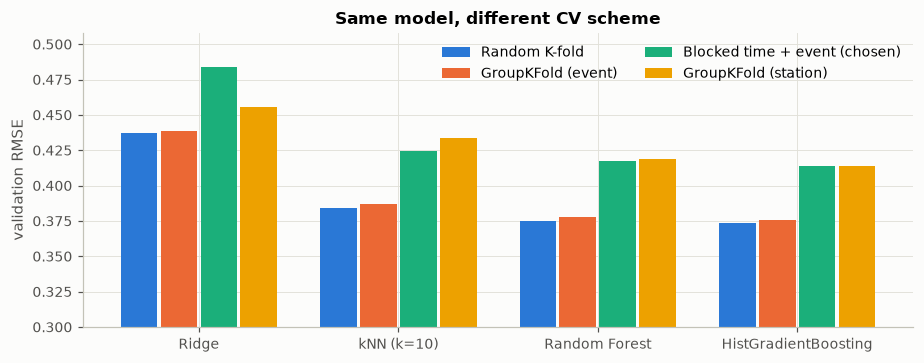

In [5]:
st_dev = dev["station_code"].to_numpy()
schemes = {
    "Random K-fold": list(KFold(5, shuffle=True, random_state=SEED).split(X_dev)),
    "GroupKFold (event)": list(GroupKFold(5, shuffle=True, random_state=SEED).split(X_dev, y_dev, ev_dev)),
    "Blocked time + event (chosen)": blocked_cv,
    "GroupKFold (station)": list(GroupKFold(5, shuffle=True, random_state=SEED).split(X_dev, y_dev, st_dev)),
}
probe_models = {
    "Mean baseline": DummyRegressor(),
    "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "kNN (k=10)": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor(10, weights="distance"))]),
    "Random Forest": RandomForestRegressor(150, max_features=0.33, min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.06, random_state=SEED),
}
scheme_rmse = pd.DataFrame({
    sname: {mname: rmse(y_dev, cross_val_predict(clone(model), X_dev, y_dev, cv=cv))
            for mname, model in probe_models.items()}
    for sname, cv in schemes.items()})
scheme_rmse["Random K-fold optimism vs chosen"] = scheme_rmse["Blocked time + event (chosen)"] - scheme_rmse["Random K-fold"]
print("Validation RMSE (out-of-fold, magnitude units)")
print(scheme_rmse.round(3).to_string())

fig, ax = plt.subplots(figsize=(8.5, 3.4))
plot_models = [m for m in probe_models if m != "Mean baseline"]
xpos = np.arange(len(plot_models)); wbar = 0.2
for j, (sname, col) in enumerate(zip(schemes, [C["blue"], C["orange"], C["aqua"], C["yellow"]])):
    ax.bar(xpos + (j - 1.5) * wbar, scheme_rmse.loc[plot_models, sname], wbar * 0.92, color=col, label=sname)
ax.set_xticks(xpos); ax.set_xticklabels(plot_models)
ax.set_ylim(0.3, None); ax.set_ylabel("validation RMSE")
ax.set_title("Same model, different CV scheme")
ax.legend(ncol=2, loc="upper right")
plt.tight_layout(); plt.show()

## 5. Model selection on validation data only

Four architectures are tuned with `RandomizedSearchCV` using the blocked, event-grouped folds. Two details keep the validation folds clean:

- `StandardScaler` lives inside each `Pipeline`, so scaling statistics come from the training folds only.
- Built-in early stopping is switched off for the MLP and the boosted trees. Both carve their internal validation set out of the training rows at random, which splits events and defeats the grouping. The number of epochs / boosting rounds is tuned by the blocked CV instead.

**Selection rule (fixed before looking at any result):** the final model is the candidate with the lowest mean blocked-CV RMSE.

In [6]:
search_spaces = {
    "Ridge": (Pipeline([("scaler", StandardScaler()), ("model", Ridge())]),
              {"model__alpha": loguniform(1e-2, 1e3)}, 10),
    "Random Forest": (RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=1),
                      {"max_features": [0.2, 0.33, 0.5, 0.8], "min_samples_leaf": randint(1, 10),
                       "max_depth": [None, 12, 20]}, 6),
    "HistGradientBoosting": (HistGradientBoostingRegressor(early_stopping=False, random_state=SEED),
                             {"learning_rate": loguniform(0.02, 0.2), "max_iter": randint(100, 600),
                              "max_leaf_nodes": randint(8, 48), "min_samples_leaf": randint(10, 60),
                              "l2_regularization": loguniform(1e-3, 10)}, 12),
    "Neural Network (MLP)": (Pipeline([("scaler", StandardScaler()),
                                       ("model", MLPRegressor(early_stopping=False, random_state=SEED))]),
                             {"model__hidden_layer_sizes": [(32,), (64, 32), (128, 64)],
                              "model__alpha": loguniform(1e-4, 1.0),
                              "model__learning_rate_init": loguniform(3e-4, 1e-2),
                              "model__max_iter": [40, 80, 150]}, 8),
}

tuned, rows, fold_scores = {}, [], {}
for name, (est, space, n_iter) in search_spaces.items():
    start = time.time()
    search = RandomizedSearchCV(est, space, n_iter=n_iter, scoring="neg_root_mean_squared_error",
                                cv=blocked_cv, random_state=SEED, n_jobs=N_JOBS, refit=False)
    search.fit(X_dev, y_dev)
    best = search.best_index_
    tuned[name] = clone(est).set_params(**search.best_params_)
    fold_scores[name] = np.array([-search.cv_results_[f"split{k}_test_score"][best] for k in range(N_BLOCKS)])
    rows.append({"Model": name, "CV RMSE (mean)": fold_scores[name].mean(), "CV RMSE (fold sd)": fold_scores[name].std(ddof=1),
                 "Search time (s)": time.time() - start, "Best parameters": search.best_params_})

fold_scores["Mean baseline"] = np.array([rmse(y_dev[va], np.full(len(va), y_dev[tr].mean())) for tr, va in blocked_cv])
rows.append({"Model": "Mean baseline", "CV RMSE (mean)": fold_scores["Mean baseline"].mean(),
             "CV RMSE (fold sd)": fold_scores["Mean baseline"].std(ddof=1), "Search time (s)": 0.0, "Best parameters": {}})
selection = pd.DataFrame(rows).sort_values("CV RMSE (mean)").reset_index(drop=True)
with pd.option_context("display.max_colwidth", 200, "display.width", 250):
    print(selection.round(4).to_string(index=False))

best_name = selection.loc[0, "Model"]
print(f"\nSelected by the pre-declared rule: {best_name}")

               Model  CV RMSE (mean)  CV RMSE (fold sd)  Search time (s)                                                                                                                                        Best parameters
HistGradientBoosting          0.4103             0.0669          15.0465        {'l2_regularization': 0.12563152773938666, 'learning_rate': 0.05022164887854354, 'max_iter': 575, 'max_leaf_nodes': 23, 'min_samples_leaf': 24}
Neural Network (MLP)          0.4152             0.0638          49.5187 {'model__alpha': 0.0007068974950624604, 'model__hidden_layer_sizes': (32,), 'model__learning_rate_init': 0.0026149941481368295, 'model__max_iter': 80}
       Random Forest          0.4164             0.0716          67.8407                                                                                         {'max_depth': 20, 'max_features': 0.33, 'min_samples_leaf': 5}
               Ridge          0.4635             0.0741           2.0437                                

Pooled out-of-fold validation metrics (blocked, event-grouped CV)
                       RMSE    MAE     R2   Bias
HistGradientBoosting  0.413  0.299  0.681 -0.024
Neural Network (MLP)  0.417  0.302  0.674 -0.031
Random Forest         0.419  0.303  0.671 -0.020
Ridge                 0.466  0.340  0.593 -0.014
Mean baseline         0.734  0.594 -0.010  0.001


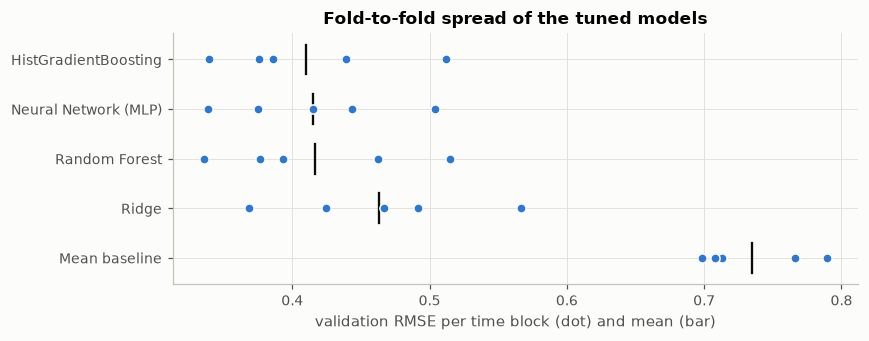

In [7]:
# Out-of-fold validation predictions for every tuned model (reused in Sections 7 and 8)
oof = {name: cross_val_predict(clone(model), X_dev, y_dev, cv=blocked_cv, n_jobs=(1 if name == "Random Forest" else N_JOBS))
       for name, model in tuned.items()}
tuned["Random Forest"].set_params(n_jobs=N_JOBS)
oof["Mean baseline"] = np.empty_like(y_dev)
for tr, va in blocked_cv:
    oof["Mean baseline"][va] = y_dev[tr].mean()

val_table = pd.DataFrame({name: metrics(y_dev, p) for name, p in oof.items()}).T.sort_values("RMSE")
print("Pooled out-of-fold validation metrics (blocked, event-grouped CV)")
print(val_table.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 3.2))
names = list(val_table.index)
for i, name in enumerate(names):
    ax.scatter(fold_scores[name], np.full(N_BLOCKS, i), s=36, color=C["blue"], edgecolor="#fcfcfb", linewidth=1, zorder=3)
    ax.plot([fold_scores[name].mean()] * 2, [i - 0.3, i + 0.3], color=C["ink"], lw=1.5)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.invert_yaxis()
ax.set_xlabel("validation RMSE per time block (dot) and mean (bar)")
ax.set_title("Fold-to-fold spread of the tuned models")
plt.tight_layout(); plt.show()

## 6. Performance across training rounds

All curves below are fitted on development blocks 1–4 and validated on block 5 (the latest development period), mirroring the direction of the final test. Training-set curves are drawn only as a reference for the generalisation gap.

HGB: best validation RMSE 0.511 at round 532; at round 800: 0.511
MLP: best validation RMSE 0.497 at epoch 84; at epoch 200: 0.499
RF @ 400 trees: out-of-bag RMSE 0.350 vs blocked validation RMSE 0.514


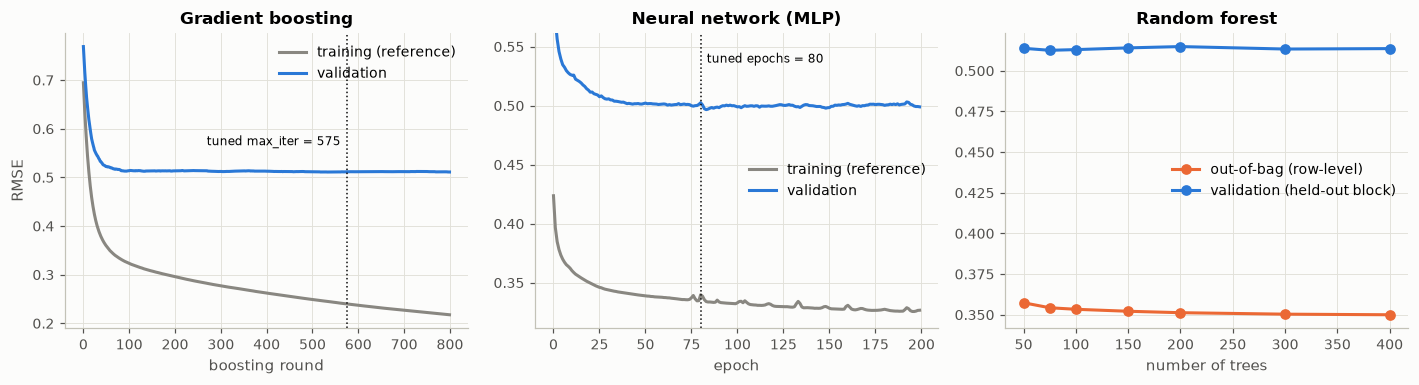

In [8]:
Xf, yf, Xv, yv = X_dev[fit_idx], y_dev[fit_idx], X_dev[val_idx], y_dev[val_idx]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

# (a) Gradient boosting: error after each boosting round
hgb_long = clone(tuned["HistGradientBoosting"]).set_params(max_iter=800).fit(Xf, yf)
tr_curve = [rmse(yf, p) for p in hgb_long.staged_predict(Xf)]
va_curve = [rmse(yv, p) for p in hgb_long.staged_predict(Xv)]
ax = axes[0]
ax.plot(tr_curve, color=C["muted"], label="training (reference)")
ax.plot(va_curve, color=C["blue"], label="validation")
tuned_iter = tuned["HistGradientBoosting"].get_params()["max_iter"]
ax.axvline(tuned_iter, color=C["ink"], lw=1, ls=":")
ax.annotate(f"tuned max_iter = {tuned_iter}", (tuned_iter, 0.62), xycoords=("data", "axes fraction"), xytext=(-4, 0), textcoords="offset points", ha="right", fontsize=8)
ax.set_title("Gradient boosting"); ax.set_xlabel("boosting round"); ax.set_ylabel("RMSE"); ax.legend()
print(f"HGB: best validation RMSE {min(va_curve):.3f} at round {int(np.argmin(va_curve)) + 1}; "
      f"at round 800: {va_curve[-1]:.3f}")

# (b) MLP: error after each epoch
scaler = StandardScaler().fit(Xf)
mlp_params = {k: v for k, v in tuned["Neural Network (MLP)"].named_steps["model"].get_params().items() if k != "max_iter"}
mlp = MLPRegressor(**mlp_params)
N_EPOCHS = 200
mlp_tr, mlp_va = [], []
Xf_s, Xv_s = scaler.transform(Xf), scaler.transform(Xv)
for _ in range(N_EPOCHS):
    mlp.partial_fit(Xf_s, yf)
    mlp_tr.append(rmse(yf, mlp.predict(Xf_s))); mlp_va.append(rmse(yv, mlp.predict(Xv_s)))
ax = axes[1]
ax.plot(mlp_tr, color=C["muted"], label="training (reference)")
ax.plot(mlp_va, color=C["blue"], label="validation")
tuned_ep = tuned["Neural Network (MLP)"].get_params()["model__max_iter"]
ax.axvline(tuned_ep, color=C["ink"], lw=1, ls=":")
ax.annotate(f"tuned epochs = {tuned_ep}", (tuned_ep, 0.9), xycoords=("data", "axes fraction"), xytext=(4, 0), textcoords="offset points", fontsize=8)
ax.set_ylim(None, max(mlp_va[5:]) * 1.05)
ax.set_title("Neural network (MLP)"); ax.set_xlabel("epoch"); ax.legend()
print(f"MLP: best validation RMSE {min(mlp_va):.3f} at epoch {int(np.argmin(mlp_va)) + 1}; at epoch {N_EPOCHS}: {mlp_va[-1]:.3f}")

# (c) Random forest: error as trees are added, and the built-in out-of-bag estimate
rf_params = {k: v for k, v in tuned["Random Forest"].get_params().items() if k not in ("n_estimators", "n_jobs")}
rf = RandomForestRegressor(**{**rf_params, "warm_start": True, "oob_score": True, "n_jobs": N_JOBS, "n_estimators": 50})
tree_grid = [50, 75, 100, 150, 200, 300, 400]
rf_oob, rf_va = [], []
for n in tree_grid:
    rf.set_params(n_estimators=n).fit(Xf, yf)
    rf_oob.append(rmse(yf, rf.oob_prediction_)); rf_va.append(rmse(yv, rf.predict(Xv)))
ax = axes[2]
ax.plot(tree_grid, rf_oob, color=C["orange"], marker="o", label="out-of-bag (row-level)")
ax.plot(tree_grid, rf_va, color=C["blue"], marker="o", label="validation (held-out block)")
ax.set_title("Random forest"); ax.set_xlabel("number of trees"); ax.legend()
print(f"RF @ {tree_grid[-1]} trees: out-of-bag RMSE {rf_oob[-1]:.3f} vs blocked validation RMSE {rf_va[-1]:.3f}")
plt.tight_layout(); plt.show()

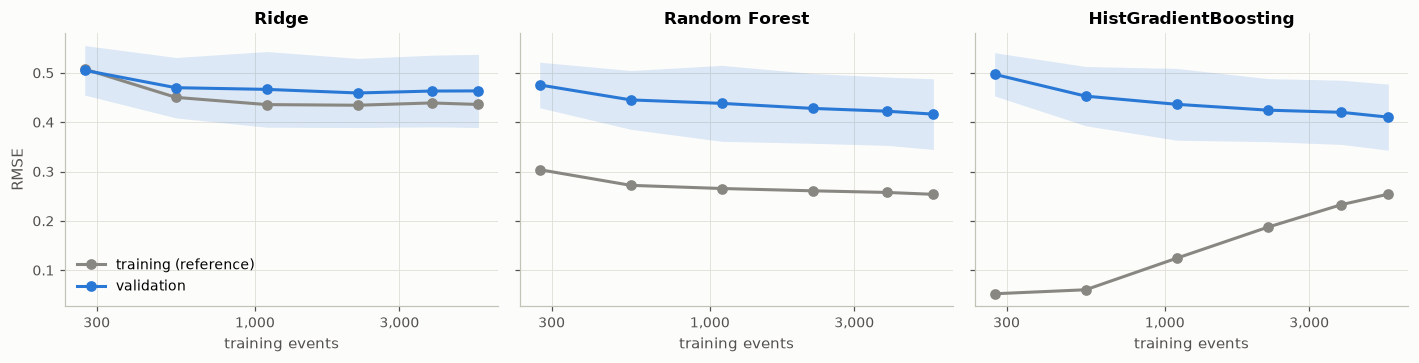

model     HistGradientBoosting  Random Forest  Ridge
n_events                                            
274.0                    0.497          0.476  0.505
548.0                    0.453          0.445  0.470
1095.6                   0.436          0.438  0.467
2191.0                   0.425          0.428  0.459
3834.6                   0.420          0.422  0.463
5477.6                   0.410          0.416  0.464


In [9]:
# Learning curves: validation error versus number of training events (blocked CV, events subsampled)
fractions = [0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
lc_models = ["Ridge", "Random Forest", "HistGradientBoosting"]

def lc_point(name, frac, k):
    tr, va = blocked_cv[k]
    rng = np.random.default_rng(SEED + k)
    events = np.unique(ev_dev[tr])
    keep = rng.choice(events, int(round(frac * len(events))), replace=False)
    sub = tr[np.isin(ev_dev[tr], keep)]
    model = clone(tuned[name])
    if name == "Random Forest":
        model.set_params(n_jobs=1)
    model.fit(X_dev[sub], y_dev[sub])
    return name, frac, len(keep), rmse(y_dev[sub], model.predict(X_dev[sub])), rmse(y_dev[va], model.predict(X_dev[va]))

lc = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(lc_point)(n, f, k) for n in lc_models for f in fractions for k in range(N_BLOCKS)),
                  columns=["model", "fraction", "n_events", "train_rmse", "val_rmse"])
lc_mean = lc.groupby(["model", "fraction"]).agg(n_events=("n_events", "mean"), train=("train_rmse", "mean"),
                                               val=("val_rmse", "mean"), val_sd=("val_rmse", "std")).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, name in zip(axes, lc_models):
    d = lc_mean[lc_mean["model"] == name]
    ax.plot(d["n_events"], d["train"], color=C["muted"], marker="o", label="training (reference)")
    ax.plot(d["n_events"], d["val"], color=C["blue"], marker="o", label="validation")
    ax.fill_between(d["n_events"], d["val"] - d["val_sd"], d["val"] + d["val_sd"], color=C["blue"], alpha=0.15, lw=0)
    ax.set_xscale("log"); ax.set_title(name); ax.set_xlabel("training events")
    ax.set_xticks([300, 1000, 3000]); ax.set_xticklabels(["300", "1,000", "3,000"]); ax.minorticks_off()
axes[0].set_ylabel("RMSE"); axes[0].legend()
plt.tight_layout(); plt.show()
print(lc_mean.pivot(index="n_events", columns="model", values="val").round(3).to_string())

## 7. Bootstrapping and bagging

### 7.1 Bootstrap confidence intervals: resample events, not rows

A bootstrap is only valid if the resampled unit is independent. Rows are not (Section 2), so the bootstrap resamples whole **events** with replacement. The row-level bootstrap is shown next to it to make the difference visible.

In [10]:
def bootstrap_metrics(y, pred, groups=None, B=2000, seed=SEED):
    # Bootstrap distribution of RMSE / MAE / R2 / bias. groups=None resamples rows; otherwise whole groups.
    y, pred = np.asarray(y, float), np.asarray(pred, float)
    codes = np.arange(len(y)) if groups is None else pd.factorize(groups)[0]
    G = codes.max() + 1
    e = pred - y
    stats = np.column_stack([np.bincount(codes, minlength=G), np.bincount(codes, e ** 2), np.bincount(codes, np.abs(e)),
                             np.bincount(codes, e), np.bincount(codes, y), np.bincount(codes, y ** 2)])
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(0, B, 250):                                   # chunked to bound memory
        W = rng.multinomial(G, np.full(G, 1.0 / G), size=250)    # how often each group is drawn
        out.append(W @ stats)
    n, sse, sae, se, sy, syy = np.vstack(out)[:B].T
    return {"RMSE": np.sqrt(sse / n), "MAE": sae / n, "Bias": se / n, "R2": 1 - sse / (syy - sy ** 2 / n)}

def ci(samples):
    return np.percentile(samples, [2.5, 97.5])

rows = []
for name in val_table.index:
    ev_bs = bootstrap_metrics(y_dev, oof[name], ev_dev)
    row_bs = bootstrap_metrics(y_dev, oof[name], None)
    lo, hi = ci(ev_bs["RMSE"]); rlo, rhi = ci(row_bs["RMSE"])
    rows.append({"Model": name, "Val RMSE": val_table.loc[name, "RMSE"], "95% CI (event bootstrap)": f"[{lo:.3f}, {hi:.3f}]",
                 "95% CI (row bootstrap)": f"[{rlo:.3f}, {rhi:.3f}]", "CI width ratio event/row": (hi - lo) / (rhi - rlo)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# Paired comparison: same resampled events for both models
ranked = [n for n in val_table.index if n != "Mean baseline"]
print(f"\nPaired event bootstrap, validation RMSE difference relative to {ranked[0]}:")
ref = bootstrap_metrics(y_dev, oof[ranked[0]], ev_dev)["RMSE"]
for other in ranked[1:]:
    diff = bootstrap_metrics(y_dev, oof[other], ev_dev)["RMSE"] - ref
    lo, hi = ci(diff)
    print(f"  {other:<22s} {diff.mean():+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  P(worse than {ranked[0]}) = {(diff > 0).mean():.2f}")

               Model  Val RMSE 95% CI (event bootstrap) 95% CI (row bootstrap)  CI width ratio event/row
HistGradientBoosting     0.413           [0.394, 0.436]         [0.403, 0.422]                     2.095
Neural Network (MLP)     0.417           [0.399, 0.439]         [0.408, 0.427]                     2.055
       Random Forest     0.419           [0.400, 0.441]         [0.409, 0.428]                     2.153
               Ridge     0.466           [0.448, 0.487]         [0.457, 0.476]                     2.024
       Mean baseline     0.734           [0.717, 0.752]         [0.726, 0.743]                     2.117

Paired event bootstrap, validation RMSE difference relative to HistGradientBoosting:
  Neural Network (MLP)   +0.0045  95% CI [-0.0004, +0.0097]  P(worse than HistGradientBoosting) = 0.97
  Random Forest          +0.0061  95% CI [+0.0023, +0.0100]  P(worse than HistGradientBoosting) = 1.00
  Ridge                  +0.0535  95% CI [+0.0455, +0.0615]  P(worse than Hist

### 7.2 Bootstrapping the training set: model variance by architecture

Each architecture is refitted on 20 event-level bootstrap resamples of the training blocks and scored on the fixed validation block. The spread across refits is the model's sensitivity to the training sample; averaging the 20 refits is bagging.

               Model  RMSE of one refit (mean)  sd across refits  Prediction sd across refits  RMSE of averaged refits (bagged)  Gain from bagging
    Single deep tree                     0.663             0.025                        0.391                             0.526              0.138
          kNN (k=10)                     0.523             0.007                        0.122                             0.506              0.017
               Ridge                     0.568             0.008                        0.021                             0.568              0.000
Neural Network (MLP)                     0.507             0.013                        0.109                             0.494              0.013
HistGradientBoosting                     0.521             0.009                        0.093                             0.511              0.010
       Random Forest                     0.520             0.007                        0.061                         

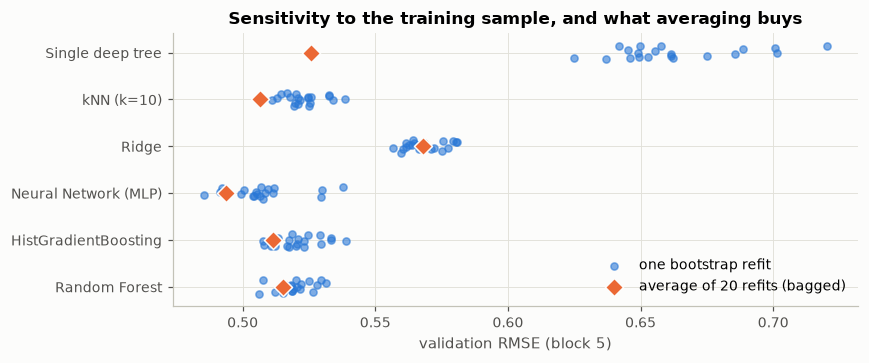

In [11]:
B_FIT = 20
boot_models = {
    "Single deep tree": DecisionTreeRegressor(random_state=SEED),
    "kNN (k=10)": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor(10, weights="distance"))]),
    "Ridge": clone(tuned["Ridge"]),
    "Neural Network (MLP)": clone(tuned["Neural Network (MLP)"]),
    "HistGradientBoosting": clone(tuned["HistGradientBoosting"]),
    "Random Forest": clone(tuned["Random Forest"]).set_params(n_jobs=1, n_estimators=100),
}
fit_events = np.unique(ev_dev[fit_idx])
rows_of_event = pd.Series(fit_idx).groupby(ev_dev[fit_idx]).apply(np.array)

def event_bootstrap_rows(seed):
    rng = np.random.default_rng(seed)
    return np.concatenate(rows_of_event.loc[rng.choice(fit_events, len(fit_events), replace=True)].to_list())

def boot_fit(name, b):
    idx = event_bootstrap_rows(SEED + b)
    model = clone(boot_models[name])
    if "random_state" in model.get_params():
        model.set_params(random_state=SEED + b)
    return name, b, model.fit(X_dev[idx], y_dev[idx]).predict(Xv)

boot_preds = {}
for name, b, p in Parallel(n_jobs=N_JOBS)(delayed(boot_fit)(n, b) for n in boot_models for b in range(B_FIT)):
    boot_preds.setdefault(name, []).append(p)

rows = []
for name, plist in boot_preds.items():
    P = np.vstack(plist)
    each = np.array([rmse(yv, p) for p in P])
    rows.append({"Model": name, "RMSE of one refit (mean)": each.mean(), "sd across refits": each.std(ddof=1),
                 "Prediction sd across refits": P.std(axis=0, ddof=1).mean(),
                 "RMSE of averaged refits (bagged)": rmse(yv, P.mean(axis=0))})
boot_table = pd.DataFrame(rows)
boot_table["Gain from bagging"] = boot_table["RMSE of one refit (mean)"] - boot_table["RMSE of averaged refits (bagged)"]
print(boot_table.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.4))
for i, name in enumerate(boot_preds):
    each = [rmse(yv, p) for p in boot_preds[name]]
    ax.scatter(each, np.full(B_FIT, i) + np.random.default_rng(i).uniform(-0.15, 0.15, B_FIT), s=22, color=C["blue"], alpha=0.6,
               label="one bootstrap refit" if i == 0 else None)
    ax.scatter(boot_table.loc[i, "RMSE of averaged refits (bagged)"], i, s=70, marker="D", color=C["orange"], edgecolor="#fcfcfb",
               zorder=3, label="average of 20 refits (bagged)" if i == 0 else None)
ax.set_yticks(range(len(boot_preds))); ax.set_yticklabels(list(boot_preds)); ax.invert_yaxis()
ax.set_xlabel("validation RMSE (block 5)"); ax.set_title("Sensitivity to the training sample, and what averaging buys")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

### 7.3 Bagging across base learners and data variations

`BaggingRegressor` is wrapped around four different base learners, then the resampling recipe is varied for the tree base learner: bag size (`max_samples`), feature subsampling (`max_features`, the random-subspace method), sampling without replacement (pasting), and resampling whole events instead of rows. All scores are blocked-CV validation RMSE.

In [12]:
def cv_rmse(model):
    return rmse(y_dev, cross_val_predict(model, X_dev, y_dev, cv=blocked_cv))

def bag(base, n=30, **kw):
    return BaggingRegressor(clone(base), n_estimators=n, random_state=SEED, n_jobs=N_JOBS, **kw)

bases = {
    "Deep decision tree": (DecisionTreeRegressor(random_state=SEED), 30),
    "kNN (k=10)": (boot_models["kNN (k=10)"], 30),
    "Ridge": (tuned["Ridge"], 30),
    "Neural Network (MLP)": (tuned["Neural Network (MLP)"], 10),
}
rows = []
for name, (base, n) in bases.items():
    single, bagged = cv_rmse(clone(base)), cv_rmse(bag(base, n))
    rows.append({"Base learner": name, "Bag size": n, "Single model": single, "Bagged": bagged, "Change": bagged - single})
bag_arch = pd.DataFrame(rows)
print("Bagging across architectures (validation RMSE)")
print(bag_arch.round(3).to_string(index=False))

# Data variations with the tree base learner
tree = DecisionTreeRegressor(random_state=SEED)
variations = {
    "rows, bootstrap, 100% samples (standard)": bag(tree),
    "rows, bootstrap, 50% samples": bag(tree, max_samples=0.5),
    "rows, bootstrap, 20% samples": bag(tree, max_samples=0.2),
    "rows, pasting (no replacement), 50% samples": bag(tree, max_samples=0.5, bootstrap=False),
    "rows, bootstrap + 50% of features per tree": bag(tree, max_features=0.5),
    "rows, bootstrap + 30% of features per tree": bag(tree, max_features=0.3),
}
var_rows = [{"Variation (30 trees)": k, "Validation RMSE": cv_rmse(v)} for k, v in variations.items()]

def event_bagged_tree_fold(k, n=30):
    # Bagging where each bag resamples whole events (the independent unit) rather than rows.
    tr, va = blocked_cv[k]
    groups = pd.Series(tr).groupby(ev_dev[tr]).apply(np.array)
    rng = np.random.default_rng(SEED + k)
    pred = np.zeros(len(va))
    for b in range(n):
        idx = np.concatenate(groups.loc[rng.choice(groups.index, len(groups), replace=True)].to_list())
        pred += DecisionTreeRegressor(random_state=b).fit(X_dev[idx], y_dev[idx]).predict(X_dev[va])
    return va, pred / n

p_event = np.empty_like(y_dev)
for va, p in Parallel(n_jobs=N_BLOCKS)(delayed(event_bagged_tree_fold)(k) for k in range(N_BLOCKS)):
    p_event[va] = p
var_rows.append({"Variation (30 trees)": "events, bootstrap, 100% of events", "Validation RMSE": rmse(y_dev, p_event)})
var_rows.append({"Variation (30 trees)": "(reference) single deep tree", "Validation RMSE": bag_arch.loc[0, "Single model"]})
bag_var = pd.DataFrame(var_rows)
print("\nBagging data variations, tree base learner")
print(bag_var.round(3).to_string(index=False))

Bagging across architectures (validation RMSE)
        Base learner  Bag size  Single model  Bagged  Change
  Deep decision tree        30         0.571   0.424  -0.147
          kNN (k=10)        30         0.424   0.422  -0.002
               Ridge        30         0.466   0.466  -0.000
Neural Network (MLP)        10         0.417   0.420   0.002

Bagging data variations, tree base learner
                       Variation (30 trees)  Validation RMSE
   rows, bootstrap, 100% samples (standard)            0.424
               rows, bootstrap, 50% samples            0.424
               rows, bootstrap, 20% samples            0.434
rows, pasting (no replacement), 50% samples            0.426
 rows, bootstrap + 50% of features per tree            0.422
 rows, bootstrap + 30% of features per tree            0.438
          events, bootstrap, 100% of events            0.425
               (reference) single deep tree            0.571


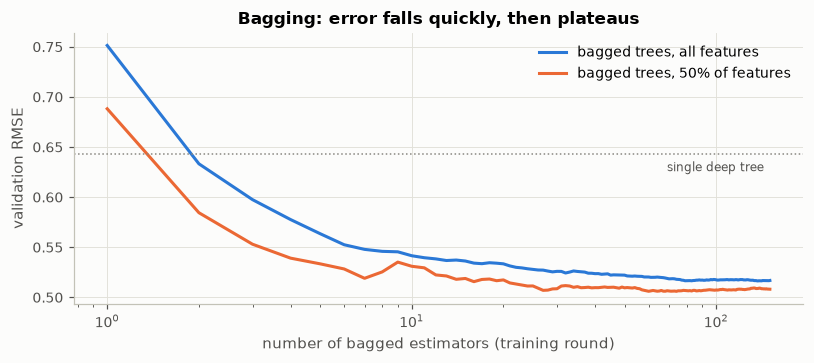

bagged trees, all features: 1 est. 0.751 | 10 est. 0.542 | 50 est. 0.522 | 150 est. 0.517
bagged trees, 50% of features: 1 est. 0.688 | 10 est. 0.531 | 50 est. 0.510 | 150 est. 0.508


In [13]:
# Bagging across rounds: validation error as estimators are added (fit on blocks 1-4, validate on block 5)
N_BAG = 150
curves = {}
for label, kw in [("bagged trees, all features", {}), ("bagged trees, 50% of features", {"max_features": 0.5})]:
    b = bag(tree, N_BAG, **kw).fit(Xf, yf)
    P = np.vstack([est.predict(Xv[:, f]) for est, f in zip(b.estimators_, b.estimators_features_)])
    curves[label] = [rmse(yv, m) for m in np.cumsum(P, axis=0) / np.arange(1, N_BAG + 1)[:, None]]
single_tree = rmse(yv, clone(tree).fit(Xf, yf).predict(Xv))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for (label, curve), col in zip(curves.items(), [C["blue"], C["orange"]]):
    ax.plot(np.arange(1, N_BAG + 1), curve, color=col, label=label)
ax.axhline(single_tree, color=C["muted"], lw=1, ls=":")
ax.annotate("single deep tree", (N_BAG, single_tree), xytext=(-4, -11), textcoords="offset points", ha="right", fontsize=8, color="#52514e")
ax.set_xscale("log"); ax.set_xlabel("number of bagged estimators (training round)"); ax.set_ylabel("validation RMSE")
ax.set_title("Bagging: error falls quickly, then plateaus"); ax.legend()
plt.tight_layout(); plt.show()
for label, curve in curves.items():
    print(f"{label}: 1 est. {curve[0]:.3f} | 10 est. {curve[9]:.3f} | 50 est. {curve[49]:.3f} | {N_BAG} est. {curve[-1]:.3f}")

## 8. Generality: performance on diverse subsets

Two kinds of test, both on development data with the selected model:

- **8.1 Subset breakdown.** The out-of-fold validation predictions are sliced by magnitude, instrument, network, source type, distance, noise and time. This shows where the pooled score hides weak spots.
- **8.2 Distribution-shift holdouts.** A whole category is removed from training and used as validation (unseen stations, unseen network, unseen instrument type, unseen magnitude range, forward in time). Any event with a recording on the validation side is also removed from the training side.

Out-of-fold validation performance of HistGradientBoosting by subset (overall RMSE 0.413)
                 Family        Subset     n  events  RMSE   MAE   Bias
              Magnitude         M < 1  4982    2631 0.457 0.313  0.226
              Magnitude     1 ≤ M < 2  7291    3098 0.326 0.253 -0.076
              Magnitude     2 ≤ M < 3  2679    1002 0.469 0.359 -0.286
              Magnitude         M ≥ 3   280     116 0.820 0.651 -0.609
                Channel            BH  3889    2661 0.521 0.362 -0.048
                Channel            EH 11067    5860 0.368 0.277 -0.015
                Channel            HH   276     242 0.362 0.266 -0.032
                Network            CC   105      95 0.604 0.486  0.286
                Network            PB    94      71 0.495 0.350 -0.201
                Network            TA  1431     878 0.612 0.415 -0.067
                Network            UO   270     214 0.503 0.321 -0.037
                Network            US   283     281 0.610 

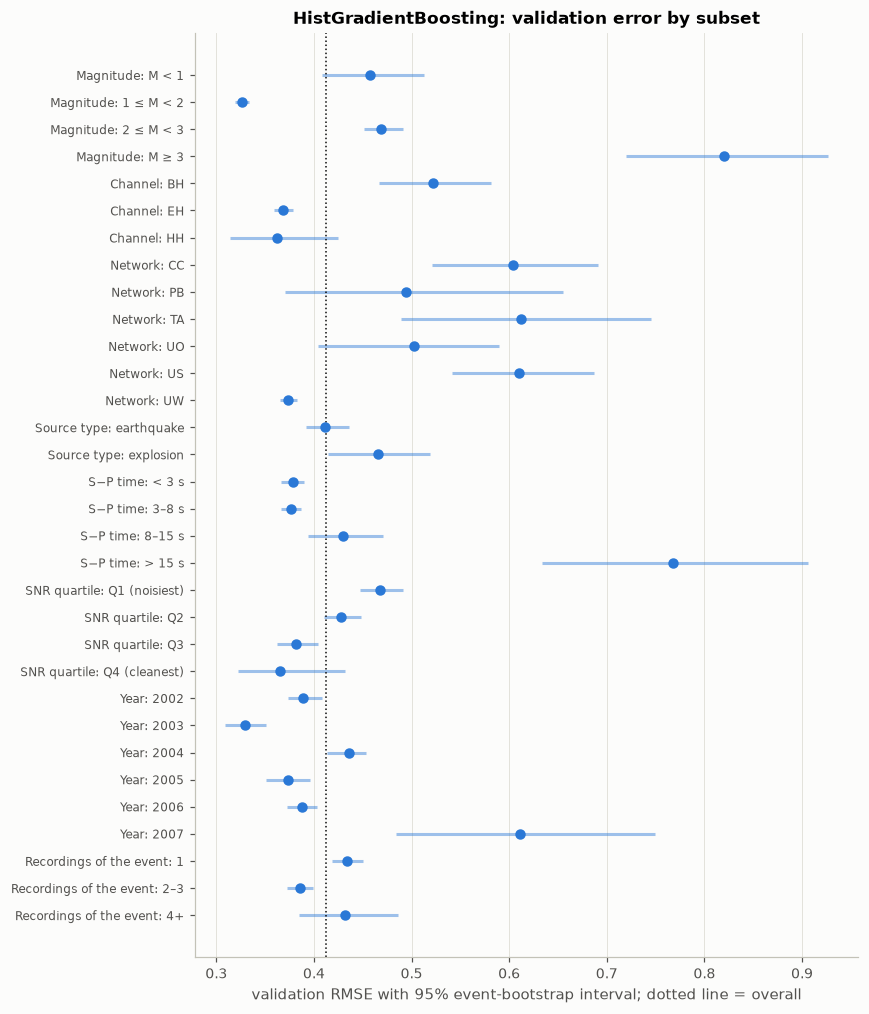

In [14]:
p_best = oof[best_name]
sp = dev["trace_S_arrival_sample"].to_numpy() - dev["trace_P_arrival_sample"].to_numpy()
snr = feats.loc[~is_test, "log_snr"].to_numpy()
n_rec = dev["event_id"].map(dev.groupby("event_id").size()).to_numpy()
subset_defs = {
    "Magnitude": pd.cut(y_dev, [-0.01, 1, 2, 3, 9], labels=["M < 1", "1 ≤ M < 2", "2 ≤ M < 3", "M ≥ 3"], right=False),
    "Channel": dev["station_channel_code"].to_numpy(),
    "Network": dev["station_network_code"].to_numpy(),
    "Source type": dev["source_type"].to_numpy(),
    "S−P time": pd.cut(sp / FS, [0, 3, 8, 15, 100], labels=["< 3 s", "3–8 s", "8–15 s", "> 15 s"]),
    "SNR quartile": pd.qcut(snr, 4, labels=["Q1 (noisiest)", "Q2", "Q3", "Q4 (cleanest)"]),
    "Year": dev["origin_time"].dt.year.to_numpy(),
    "Recordings of the event": pd.cut(n_rec, [0, 1, 3, 100], labels=["1", "2–3", "4+"]),
}
rows = []
for family, labels in subset_defs.items():
    labels = np.asarray(labels.astype(str) if hasattr(labels, "astype") else labels).astype(str)
    order = list(pd.unique(pd.Series(subset_defs[family]).sort_values().astype(str)))
    for lab in order:
        mask = labels == lab
        if mask.sum() < 30:
            continue
        lo, hi = ci(bootstrap_metrics(y_dev[mask], p_best[mask], ev_dev[mask], B=500)["RMSE"])
        rows.append({"Family": family, "Subset": lab, "n": int(mask.sum()), "events": len(np.unique(ev_dev[mask])),
                     **{k: v for k, v in metrics(y_dev[mask], p_best[mask]).items() if k != "R2"}, "lo": lo, "hi": hi})
subsets = pd.DataFrame(rows)
print(f"Out-of-fold validation performance of {best_name} by subset (overall RMSE {rmse(y_dev, p_best):.3f})")
print(subsets.drop(columns=["lo", "hi"]).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 0.26 * len(subsets) + 1))
ypos = np.arange(len(subsets))
ax.hlines(ypos, subsets["lo"], subsets["hi"], color=C["blue"], lw=2, alpha=0.45)
ax.scatter(subsets["RMSE"], ypos, s=34, color=C["blue"], zorder=3)
ax.axvline(rmse(y_dev, p_best), color=C["ink"], lw=1, ls=":")
ax.set_yticks(ypos); ax.set_yticklabels(subsets["Family"] + ": " + subsets["Subset"], fontsize=8); ax.invert_yaxis()
ax.set_xlabel("validation RMSE with 95% event-bootstrap interval; dotted line = overall")
ax.set_title(f"{best_name}: validation error by subset")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

                                       Held-out condition  n val  n train  RMSE when held out  Bias when held out  RMSE same rows, blocked CV  Degradation
                                       Unseen network: TA   1431  12477.0               0.643              -0.110                       0.612        0.031
                                       Unseen network: PB     94  14896.0               0.495              -0.193                       0.495        0.000
                                       Unseen network: US    283  14610.0               0.729              -0.154                       0.610        0.119
                                       Unseen network: UO    270  14736.0               0.527              -0.019                       0.503        0.024
                                       Unseen network: CC    105  14852.0               0.932               0.768                       0.604        0.328
                               Unseen instrument type: EH  11067   140

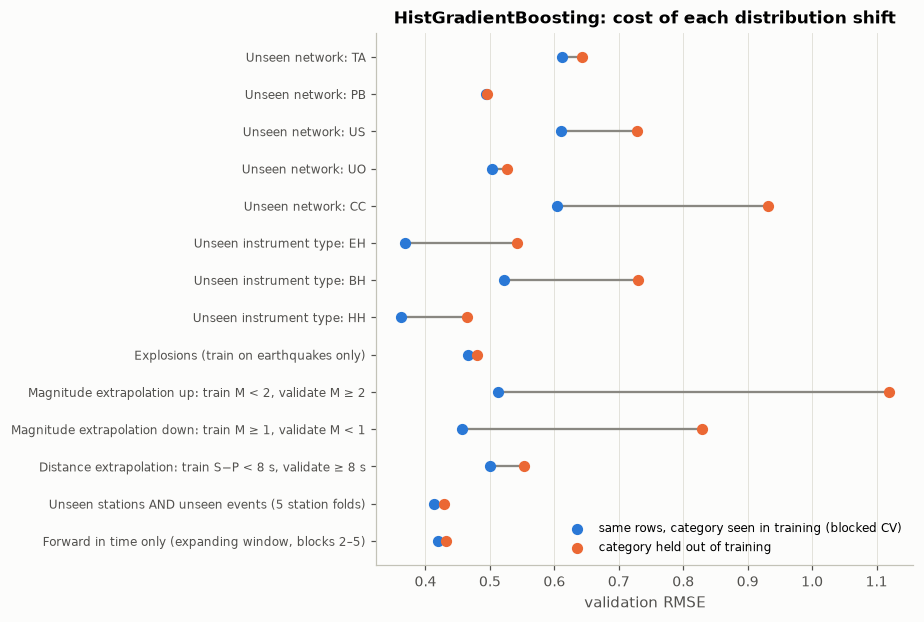

In [15]:
def shift_holdout(label, val_mask, train_mask=None):
    # Train without the held-out category (and without any event that appears in it); validate on it.
    val_mask = np.asarray(val_mask)
    train_mask = ~val_mask if train_mask is None else np.asarray(train_mask)
    train_mask = train_mask & ~np.isin(ev_dev, np.unique(ev_dev[val_mask]))
    pred = clone(tuned[best_name]).fit(X_dev[train_mask], y_dev[train_mask]).predict(X_dev[val_mask])
    m = metrics(y_dev[val_mask], pred)
    return {"Held-out condition": label, "n val": int(val_mask.sum()), "n train": int(train_mask.sum()),
            "RMSE when held out": m["RMSE"], "Bias when held out": m["Bias"],
            "RMSE same rows, blocked CV": rmse(y_dev[val_mask], p_best[val_mask])}

net, chan = dev["station_network_code"].to_numpy(), dev["station_channel_code"].to_numpy()
rows = []
for n in ["TA", "PB", "US", "UO", "CC"]:
    rows.append(shift_holdout(f"Unseen network: {n}", net == n))
for c in ["EH", "BH", "HH"]:
    rows.append(shift_holdout(f"Unseen instrument type: {c}", chan == c))
rows.append(shift_holdout("Explosions (train on earthquakes only)", dev["source_type"].to_numpy() == "explosion"))
rows.append(shift_holdout("Magnitude extrapolation up: train M < 2, validate M ≥ 2", y_dev >= 2))
rows.append(shift_holdout("Magnitude extrapolation down: train M ≥ 1, validate M < 1", y_dev < 1))
rows.append(shift_holdout("Distance extrapolation: train S−P < 8 s, validate ≥ 8 s", sp / FS >= 8))

# Unseen stations: station-grouped folds, with events on the validation side removed from training
p_station = np.empty_like(y_dev)
for tr, va in schemes["GroupKFold (station)"]:
    tr = tr[~np.isin(ev_dev[tr], np.unique(ev_dev[va]))]
    p_station[va] = clone(tuned[best_name]).fit(X_dev[tr], y_dev[tr]).predict(X_dev[va])
m = metrics(y_dev, p_station)
rows.append({"Held-out condition": "Unseen stations AND unseen events (5 station folds)", "n val": len(y_dev), "n train": np.nan,
             "RMSE when held out": m["RMSE"], "Bias when held out": m["Bias"], "RMSE same rows, blocked CV": rmse(y_dev, p_best)})

# Forward chaining (TimeSeriesSplit-style): train on blocks < k, validate on block k
p_fwd = np.full_like(y_dev, np.nan)
for k in range(1, N_BLOCKS):
    p_fwd[block == k] = clone(tuned[best_name]).fit(X_dev[block < k], y_dev[block < k]).predict(X_dev[block == k])
later = block >= 1
m = metrics(y_dev[later], p_fwd[later])
rows.append({"Held-out condition": "Forward in time only (expanding window, blocks 2–5)", "n val": int(later.sum()), "n train": np.nan,
             "RMSE when held out": m["RMSE"], "Bias when held out": m["Bias"], "RMSE same rows, blocked CV": rmse(y_dev[later], p_best[later])})

shifts = pd.DataFrame(rows)
shifts["Degradation"] = shifts["RMSE when held out"] - shifts["RMSE same rows, blocked CV"]
with pd.option_context("display.width", 250):
    print(shifts.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 0.34 * len(shifts) + 1))
ypos = np.arange(len(shifts))
ax.hlines(ypos, shifts["RMSE same rows, blocked CV"], shifts["RMSE when held out"], color=C["muted"], lw=1.5)
ax.scatter(shifts["RMSE same rows, blocked CV"], ypos, s=40, color=C["blue"], zorder=3, label="same rows, category seen in training (blocked CV)")
ax.scatter(shifts["RMSE when held out"], ypos, s=40, color=C["orange"], zorder=3, label="category held out of training")
ax.set_yticks(ypos); ax.set_yticklabels(shifts["Held-out condition"], fontsize=8); ax.invert_yaxis()
ax.set_xlabel("validation RMSE"); ax.set_title(f"{best_name}: cost of each distribution shift")
ax.grid(axis="y", visible=False); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

## 9. Final model and the single test evaluation

The model, its hyperparameters and the evaluation metrics were all fixed above using development data only. The cell below refits the selected configuration on all development data and predicts the locked test period once. `TEST_USED` guards against a second evaluation in the same session.

Event-level magnitude (the median of an event's single-station predictions) is reported alongside the per-recording score because it is how station magnitudes are combined in practice; the validation value of that metric is computed first so that it, too, has a pre-test estimate.

In [16]:
def event_median(event_ids, y, pred):
    g = pd.DataFrame({"e": event_ids, "y": y, "p": pred}).groupby("e").agg(y=("y", "first"), p=("p", "median"))
    return g["y"].to_numpy(), g["p"].to_numpy()

val_expect = {"Per recording": metrics(y_dev, oof[best_name]),
              "Per event (median of stations)": metrics(*event_median(ev_dev, y_dev, oof[best_name]))}
val_ci = ci(bootstrap_metrics(y_dev, oof[best_name], ev_dev)["RMSE"])
print("Frozen model:", best_name)
print("Hyperparameters:", {k: v for k, v in tuned[best_name].get_params().items()
                           if k in selection.loc[0, "Best parameters"]})
print(f"Validation estimate (blocked CV): RMSE {val_expect['Per recording']['RMSE']:.3f} "
      f"[95% CI {val_ci[0]:.3f}, {val_ci[1]:.3f}], fold range {fold_scores[best_name].min():.3f}–{fold_scores[best_name].max():.3f}")

Frozen model: HistGradientBoosting
Hyperparameters: {'l2_regularization': np.float64(0.12563152773938666), 'learning_rate': np.float64(0.05022164887854354), 'max_iter': 575, 'max_leaf_nodes': 23, 'min_samples_leaf': 24}
Validation estimate (blocked CV): RMSE 0.413 [95% CI 0.394, 0.436], fold range 0.340–0.512


In [17]:
# ---- THE ONLY CELL THAT TOUCHES THE TEST SET ----
assert not TEST_USED, "The test set has already been evaluated in this session."
TEST_USED = True

final_model = clone(tuned[best_name]).fit(X_dev, y_dev)
test = meta.iloc[TEST_ROWS].reset_index(drop=True)
X_test = feats.iloc[TEST_ROWS].to_numpy()
y_test = test["preferred_source_magnitude"].to_numpy()
ev_test = test["event_id"].to_numpy()
p_test = final_model.predict(X_test)
p_base = np.full(len(y_test), y_dev.mean())          # mean baseline learned on development data

test_bs = bootstrap_metrics(y_test, p_test, ev_test)
rows = []
for label, (yy, pp) in {"Per recording": (y_test, p_test),
                        "Per event (median of stations)": event_median(ev_test, y_test, p_test),
                        "Mean baseline, per recording": (y_test, p_base)}.items():
    rows.append({"Test metric": label, "n": len(yy), **metrics(yy, pp)})
test_table = pd.DataFrame(rows)
print(f"TEST SET ({len(y_test)} recordings, {len(np.unique(ev_test))} events, "
      f"{test['origin_time'].min().date()} to {test['origin_time'].max().date()})")
print(test_table.round(3).to_string(index=False))
print("\n95% event-bootstrap intervals, per recording:")
for k in ["RMSE", "MAE", "R2", "Bias"]:
    lo, hi = ci(test_bs[k]); print(f"  {k:<5s} {metrics(y_test, p_test)[k]:+.3f}  [{lo:+.3f}, {hi:+.3f}]")

compare = pd.DataFrame({"Validation (blocked CV)": val_expect["Per recording"], "Test": metrics(y_test, p_test)}).T
compare["RMSE per event"] = [val_expect["Per event (median of stations)"]["RMSE"], test_table.loc[1, "RMSE"]]
print("\nValidation estimate vs test result")
print(compare.round(3).to_string())
print(f"Test RMSE minus validation RMSE: {compare.loc['Test', 'RMSE'] - compare.loc['Validation (blocked CV)', 'RMSE']:+.3f}")

TEST SET (3408 recordings, 1208 events, 2007-05-09 to 2008-12-05)
                   Test metric    n  RMSE   MAE     R2   Bias
                 Per recording 3408 0.415 0.301  0.664 -0.031
Per event (median of stations) 1208 0.400 0.277  0.651  0.001
  Mean baseline, per recording 3408 0.716 0.573 -0.000  0.000

95% event-bootstrap intervals, per recording:
  RMSE  +0.415  [+0.389, +0.445]
  MAE   +0.301  [+0.287, +0.315]
  R2    +0.664  [+0.609, +0.712]
  Bias  -0.031  [-0.053, -0.010]

Validation estimate vs test result
                          RMSE    MAE     R2   Bias  RMSE per event
Validation (blocked CV)  0.413  0.299  0.681 -0.024           0.385
Test                     0.415  0.301  0.664 -0.031           0.400
Test RMSE minus validation RMSE: +0.002


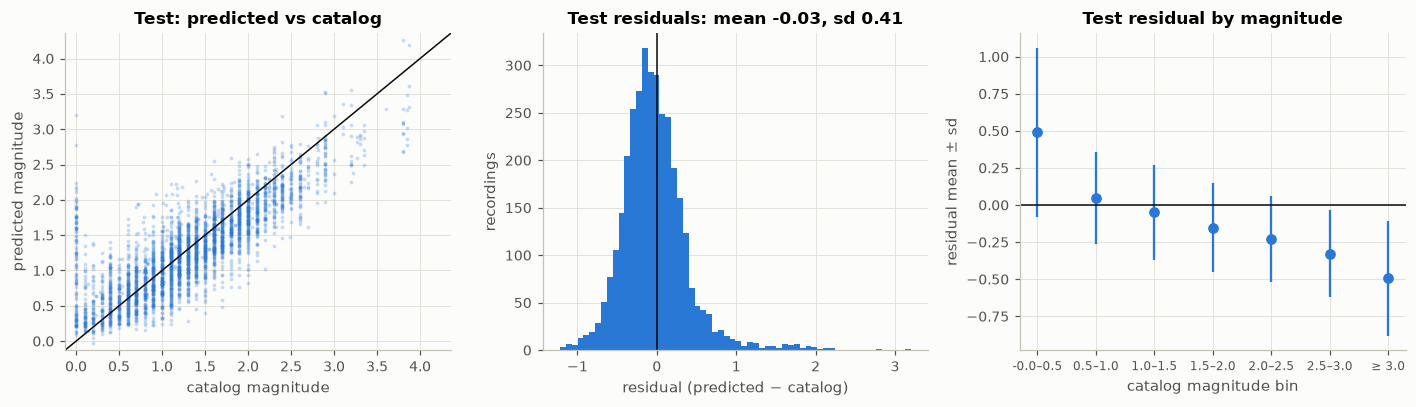

Test performance by subset (subsets with at least 30 recordings)
     Family                         Subset    n  RMSE   MAE   Bias
  Magnitude                      1 ≤ M < 2 1692 0.329 0.259 -0.094
  Magnitude                      2 ≤ M < 3  611 0.386 0.314 -0.250
  Magnitude                          M < 1 1056 0.528 0.347  0.219
  Magnitude                          M ≥ 3   49 0.625 0.565 -0.494
    Channel                             BH 1660 0.491 0.352  0.005
    Channel                             EH 1736 0.327 0.252 -0.065
    Network                             CC   78 0.496 0.400  0.267
    Network                             PB  294 0.358 0.279 -0.060
    Network                             TA 1289 0.512 0.360  0.019
    Network                             US   63 0.531 0.364 -0.038
    Network                             UW 1663 0.320 0.250 -0.078
Source type                     earthquake 3201 0.412 0.297 -0.037
Source type                      explosion  207 0.450 0.350  0.0

In [18]:
# Test-set diagnostics (reporting only; nothing here feeds back into the model)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ax = axes[0]
ax.scatter(y_test, p_test, s=6, alpha=0.25, color=C["blue"], linewidth=0)
lim = [min(y_test.min(), p_test.min()) - 0.1, max(y_test.max(), p_test.max()) + 0.1]
ax.plot(lim, lim, color=C["ink"], lw=1)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("catalog magnitude"); ax.set_ylabel("predicted magnitude")
ax.set_title("Test: predicted vs catalog")

ax = axes[1]
res = p_test - y_test
ax.hist(res, bins=60, color=C["blue"])
ax.axvline(0, color=C["ink"], lw=1)
ax.set_xlabel("residual (predicted − catalog)"); ax.set_ylabel("recordings")
ax.set_title(f"Test residuals: mean {res.mean():+.2f}, sd {res.std():.2f}")

ax = axes[2]
bins = pd.cut(y_test, [-0.01, 0.5, 1, 1.5, 2, 2.5, 3, 9], right=False)
g = pd.DataFrame({"b": bins, "r": res}).groupby("b", observed=True)["r"].agg(["mean", "std", "size"])
centers = np.arange(len(g))
ax.errorbar(centers, g["mean"], yerr=g["std"], fmt="o", color=C["blue"], ecolor=C["blue"], elinewidth=1.5, capsize=0)
ax.axhline(0, color=C["ink"], lw=1)
ax.set_xticks(centers); ax.set_xticklabels([f"{iv.left:.1f}–{iv.right:.1f}" if iv.right < 9 else "≥ 3.0" for iv in g.index], fontsize=8)
ax.set_xlabel("catalog magnitude bin"); ax.set_ylabel("residual mean ± sd")
ax.set_title("Test residual by magnitude")
plt.tight_layout(); plt.show()

seen_station = np.isin(test["station_code"], dev["station_code"].unique())
sp_t = (test["trace_S_arrival_sample"] - test["trace_P_arrival_sample"]).to_numpy() / FS
test_subsets = {
    "Magnitude": pd.cut(y_test, [-0.01, 1, 2, 3, 9], labels=["M < 1", "1 ≤ M < 2", "2 ≤ M < 3", "M ≥ 3"], right=False).astype(str),
    "Channel": test["station_channel_code"].to_numpy(),
    "Network": test["station_network_code"].to_numpy(),
    "Source type": test["source_type"].to_numpy(),
    "S−P time": np.asarray(pd.cut(sp_t, [0, 3, 8, 15, 100], labels=["< 3 s", "3–8 s", "8–15 s", "> 15 s"]).astype(str)),
    "Station": np.where(seen_station, "seen in development data", "never seen in development data"),
}
rows = []
for family, labels in test_subsets.items():
    labels = np.asarray(labels).astype(str)
    for lab in sorted(pd.unique(labels)):
        mask = labels == lab
        if mask.sum() >= 30:
            rows.append({"Family": family, "Subset": lab, "n": int(mask.sum()),
                         **{k: v for k, v in metrics(y_test[mask], p_test[mask]).items() if k != "R2"}})
print("Test performance by subset (subsets with at least 30 recordings)")
print(pd.DataFrame(rows).round(3).to_string(index=False))

## 10. Discussion

All numbers below come from the outputs above: out-of-fold validation predictions on the development period (2002 to May 2007), or the single test evaluation on the later period (May 2007 to 2008).

### Headline result

| | RMSE | MAE | R² | Bias |
| :--- | ---: | ---: | ---: | ---: |
| Validation estimate (blocked, event-grouped CV) | 0.413 [0.394, 0.436] | 0.299 | 0.681 | −0.024 |
| **Test, per recording** | **0.415 [0.389, 0.445]** | **0.301** | **0.664** | **−0.031** |
| Test, per event (median over stations) | 0.400 | 0.277 | 0.651 | +0.001 |
| Test, mean baseline | 0.716 | 0.573 | 0.000 | 0.000 |

The test RMSE is 0.002 above the validation estimate and well inside its event-bootstrap interval. The validation protocol predicted performance on unseen future events accurately. This was the purpose of the blocked, event-grouped design. Random K-fold would have reported about 0.374, roughly 10% better than the result that held up.

**What to expect on new data.** For new events recorded by stations and instrument types like those in this catalog, expect about 0.41 magnitude units RMSE per recording and about 0.40 per event. At stations never seen in training, expect about 0.6 (Section 9 test subset: 0.608 on 209 recordings). For magnitudes outside the training range (M > 4) or a new instrument type, expect substantially worse; see Section 8.2.

### How the cross-validation scheme affects the reported performance

* **Random K-fold was optimistic by 0.040–0.046 RMSE for every model that uses features. It was not optimistic for the mean baseline.** The optimism is information shared between correlated samples, not a property of any one model.
* **Most of that optimism comes from time, not from sibling recordings.** GroupKFold by event scored almost the same as random K-fold (0.376 vs 0.374 for gradient boosting). Because no feature identifies an event, recordings of the same event did not leak much. The blocked split is what matters. Instrumentation changed over the period: the broadband (BH/HH) share rose from 15% in block 1 to 43% in block 5 and 49% in the test period. Shuffled folds hide that drift; time blocks expose it.
* **The out-of-bag error is another random-row estimate, with the same flaw.** The random forest's OOB RMSE was 0.35 while its blocked validation RMSE on block 5 was 0.51 (Section 6). OOB scoring should not be used for model selection on correlated geoscience data.
* **Fold-to-fold spread is larger than the differences between models.** Blocked-CV RMSE ranged from 0.34 to 0.51 across time blocks for the same gradient-boosting model. The three best architectures differ by only 0.006. The period being predicted matters more than the choice of architecture.

### Model selection

Gradient boosting (0.413), the MLP (0.417) and the random forest (0.419) are practically tied. The paired event bootstrap shows the random forest reliably but marginally worse (+0.006, CI [+0.002, +0.010]); the MLP difference is borderline (CI includes 0). Ridge regression is clearly worse (+0.054), so the magnitude–feature relationship has non-linear structure that trees and networks capture. Gradient boosting was chosen by the rule fixed before the search (lowest mean CV RMSE). An MLP or random forest would have generalised almost as well.

### Training rounds and learning curves

* **Gradient boosting:** validation error on block 5 flattens by about 100 rounds, while training error keeps falling to 0.22 at round 800. The tuned 575 rounds is past the useful point, but the learning rate and leaf-size regularisation keep the extra rounds from causing damage (0.511 at the best round and 0.511 at round 800).
* **MLP:** validation error plateaus around 50–80 epochs (best 0.497 at epoch 84). Training past that only widens the train/validation gap.
* **Random forest:** adding trees beyond about 75 does not change validation error.
* **Learning curves:** Ridge stops improving after about 1,000 training events, and its training and validation errors converge, so it is limited by bias. The tree models are still improving slowly at 5,500 events, and the gradient-boosting train/validation gap is narrowing. More labelled events would help these models modestly. More capacity would not help Ridge.

### Bootstrapping

* **The resampling unit matters for uncertainty estimates.** Bootstrapping events gives confidence intervals about 2× wider than bootstrapping rows, for every model. A row bootstrap treats the 2.3 recordings of each event as independent evidence and overstates precision. All intervals reported here use the event bootstrap.
* **Training-set bootstraps measure each model's variance.** Across 20 bootstrap refits, a single deep tree's prediction for the same recording varied by 0.39 magnitude units on average. For Ridge it varied by 0.02, with the MLP, kNN, boosting and random forest in between.

### Bagging

* **Bagging helps only high-variance learners.** Bagging deep trees cut validation RMSE from 0.571 to 0.424 (−26%), close to the random forest and gradient boosting. Bagging Ridge (0.000), kNN (−0.002) and the MLP (+0.002) did nothing. Those models have little variance for averaging to remove. The bagging-across-rounds curve shows the gain arriving in the first 10–20 estimators and flattening after about 50.
* **Bag-size and resampling variations change little, within limits.** Half-size bags performed as well as full-size bags (0.424 vs 0.424), and pasting without replacement was nearly identical (0.426). 20% bags lost accuracy (0.434).
* **Feature subsampling has an optimum.** Giving each tree 50% of the features helped slightly (0.422; 0.508 vs 0.517 on block 5 at 150 estimators), because it decorrelates the trees, which is the idea behind random forests. 30% removed too much (0.438).
* **Event-level resampling gave the same accuracy as row-level resampling (0.425 vs 0.424).** The resampling unit matters for honest uncertainty estimates, not for the predictive accuracy of the ensemble.

### Generality across subsets

The pooled RMSE of 0.413 hides clear weak spots. The same pattern appears in validation and test:

* **Magnitude extremes regress toward the mean.** M ≥ 3 is under-predicted (validation bias −0.61; test −0.49) and M < 1 is over-predicted (+0.23 / +0.22). Large events are rare (1.8% of recordings) and tree models cannot predict beyond the targets they were trained on. When the model is trained on M < 2 and asked to predict M ≥ 2, RMSE rises to 1.12. This explains most of the poor scores in `AutoML_Hyperparameter_Tuning.ipynb`, which used exactly that split (along with a pre-event noise window as input).
* **Instruments and networks.** Broadband BH channels are harder than short-period EH channels (0.52 vs 0.37 validation; 0.49 vs 0.33 test). Networks other than UW score 0.50–0.61. Amplitudes are raw counts with no instrument-response correction, so the model has to learn gain from the channel flag, and it cannot do so for an instrument type absent from training (+0.10 to +0.21 RMSE when an instrument type is held out).
* **Distance and noise.** Error grows for S−P > 15 s (0.77) and for the noisiest quartile (0.47 vs 0.37 for the cleanest).
* **Generalisation is robust to:** new stations within the same networks (+0.016 under station-grouped folds that also exclude shared events), forward-in-time prediction (+0.013), and explosions when trained only on earthquakes (+0.014).
* **Test stations never seen in development** (209 recordings; 178 of them at Plate Boundary Observatory (PB) borehole stations, a network with only 94 development recordings) scored 0.61. That is worse than the station-fold estimate suggested, because those stations combine a new site with a network and sensor installation that is barely represented in training.

### Limitations

* Features are in raw counts. Correcting for instrument response would probably reduce the instrument and network gaps more than any change of model.
* The catalog magnitudes are themselves uncertain, mostly duration magnitudes with reported uncertainties of a few hundredths to tenths of a unit. Some of the remaining error is label noise.
* The test set is a single 19-month period from the same networks. It measures generalisation forward in time, not to a different region.
* Hyperparameter searches were small (6–12 candidates per model). The tie between the top three models suggests a larger search would not change the conclusions.